In [1]:
%load_ext autoreload
%autoreload 2
from sem2 import SEM2

In [2]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from engression.loss_func import energy_loss_two_sample
from scipy.stats import gamma

In [3]:
shape = 2.
scale = 3.
gamma_dist = torch.distributions.Gamma(concentration=shape, rate=1.0/scale)

In [4]:
# generate data
n = 1000
x = torch.Tensor(gamma_dist.sample((n,1)))

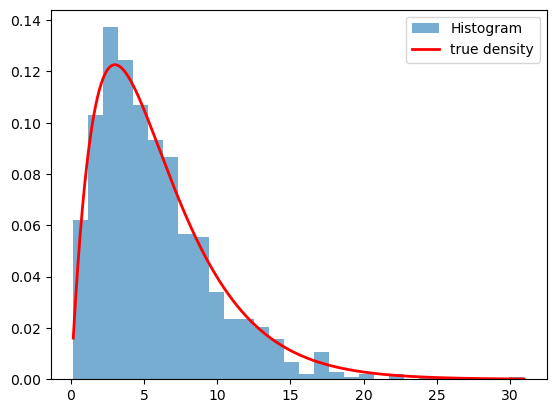

In [5]:
plt.hist(x.squeeze(1), bins=30, density=True, alpha=0.6, label='Histogram')

# Generate a range of values for plotting the theoretical density curve
xx = np.linspace(min(x), max(x), 1000)
pdf = gamma.pdf(xx, a=shape, scale=scale)

# Overlay the theoretical gamma density curve
plt.plot(xx, pdf, 'r-', lw=2, label='true density')
plt.legend(); plt.show()

In [6]:
# build model
# model = StoNet(in_dim=0, out_dim=1, num_layer=4, hidden_dim=400, noise_dim=1, add_bn=False)#, out_act='softplus')
model = SEM2("e ~ Normal(0,1); X <- n(e)")
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [12]:
# training
model.train()
for i in range(1000):
    optimizer.zero_grad()
    sample1 = model(n)
    sample2 = model(n)
    loss, s1, s2 = energy_loss_two_sample(x, sample1[:,1], sample2[:,1])
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 100 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

Iter 1 | loss: 5.6537, s1: 5.6628, s2: 0.0182
Iter 100 | loss: 2.0770, s1: 4.2203, s2: 4.2865
Iter 200 | loss: 2.1448, s1: 4.2533, s2: 4.2171
Iter 300 | loss: 2.1047, s1: 4.2934, s2: 4.3774
Iter 400 | loss: 2.1562, s1: 4.2380, s2: 4.1636
Iter 500 | loss: 2.0974, s1: 4.2141, s2: 4.2335
Iter 600 | loss: 2.1310, s1: 4.2289, s2: 4.1957
Iter 700 | loss: 2.1516, s1: 4.2028, s2: 4.1024
Iter 800 | loss: 2.1755, s1: 4.0273, s2: 3.7036
Iter 900 | loss: 2.0838, s1: 4.2961, s2: 4.4246
Iter 1000 | loss: 2.1034, s1: 4.2510, s2: 4.2952


In [14]:
# evaluation
model.eval()
with torch.no_grad():
    sample = model(n)[:,1]
sum(sample < 0)

tensor(0)

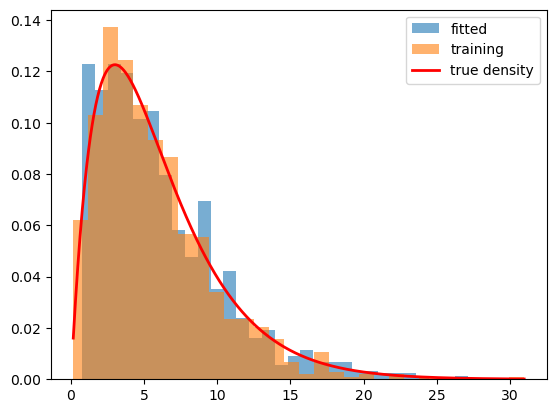

In [21]:
plt.hist(sample, bins=30, density=True, alpha=0.6, label='fitted')
plt.hist(x.squeeze(1), bins=30, density=True, alpha=0.6, label='training')
xx = np.linspace(min(x), max(x), 1000)
pdf = gamma.pdf(xx, a=shape, scale=scale)
# Overlay the theoretical gamma density curve
plt.plot(xx, pdf, 'r-', lw=2, label='true density')
plt.legend(); plt.show()